
# Evaluare 01: Învățarea supervizată
Acest test are scopul de a evalua cunoștințele tale despre importul datelor, vizualizarea acestora și utilizarea modelelor de machine learning.
Te rugăm să completezi cerințele direct în celulele dedicate fiecărei secțiuni.


## 1. Importul datelor
1. Importă biblioteca `pandas` și încarcă fișierul `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
2. Verifică dimensiunile și tipurile de date.
3. Afișează primele 5 rânduri din DataFrame și verifică prezența valorilor lipsă.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

# 1. Incarcarea setului de date
file_name = 'Human_Activity_Recognition_Using_Smartphones_Data.csv'
file_path = file_name if os.path.exists(file_name) else os.path.join('data', file_name)

df = pd.read_csv(file_path)
print(f"Fisierul a fost incarcat cu succes de la: {file_path}")

# 2. Verificarea dimensiunilor si a tipurilor de date
print("\n" + "="*50)
print("1. DIMENSIUNILE SETULUI DE DATE")
print("="*50)
print(f"Numar de randuri (instante):  {df.shape[0]}")
print(f"Numar de coloane (atribute): {df.shape[1]}")

print("\n" + "="*50)
print("2. DISTRIBUTIA TIPURILOR DE DATE")
print("="*50)
print(df.dtypes.value_counts())

# 3. Afisarea primelor 5 randuri si verificarea valorilor lipsa
print("\n" + "="*50)
print("3. PRIMELE 5 RANDURI DIN DATAFRAME")
print("="*50)
display(df.head())

print("\n" + "="*50)
print("4. VERIFICAREA VALORILOR LIPSA")
print("="*50)
total_missing = df.isnull().sum().sum()
print(f"Numarul total de valori lipsa (NaN/Null) in setul de date: {total_missing}")
if total_missing == 0:
    print("-> Setul de date este complet, nu exista valori lipsa.")
else:
    print("-> Coloane cu valori lipsa:")
    print(df.isnull().sum()[df.isnull().sum() > 0])


Fisierul a fost incarcat cu succes de la: data\Human_Activity_Recognition_Using_Smartphones_Data.csv

1. DIMENSIUNILE SETULUI DE DATE
Numar de randuri (instante):  10299
Numar de coloane (atribute): 562

2. DISTRIBUTIA TIPURILOR DE DATE
float64    561
str          1
Name: count, dtype: int64

3. PRIMELE 5 RANDURI DIN DATAFRAME


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING



4. VERIFICAREA VALORILOR LIPSA
Numarul total de valori lipsa (NaN/Null) in setul de date: 0
-> Setul de date este complet, nu exista valori lipsa.



## 2. Vizualizare date cu Matplotlib și Seaborn
1. Creează un grafic scatter care să afișeze relația dintre două coloane numeric.
2. Utilizează Seaborn pentru a crea o hartă de căldură (heatmap) a corelațiilor dintre coloane.


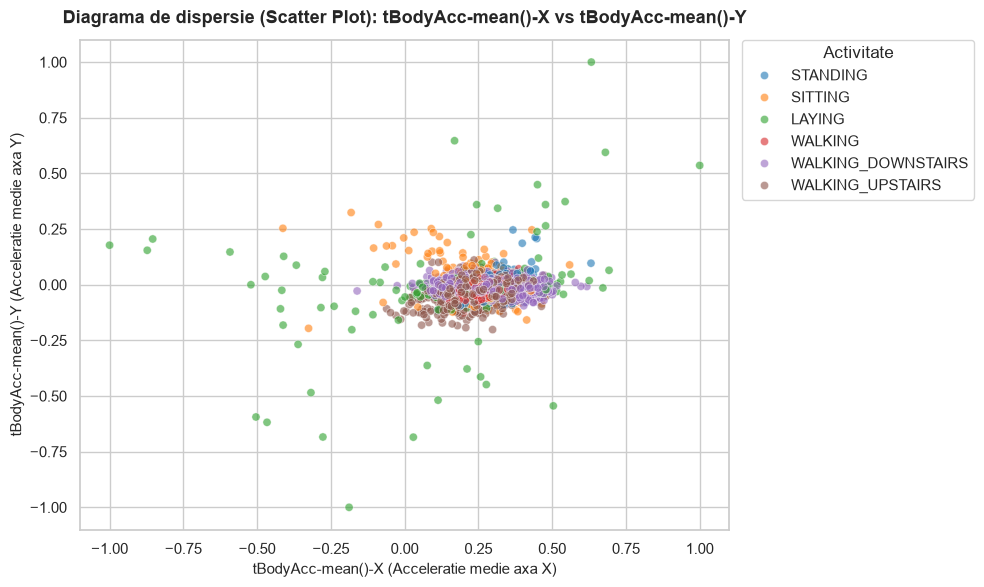

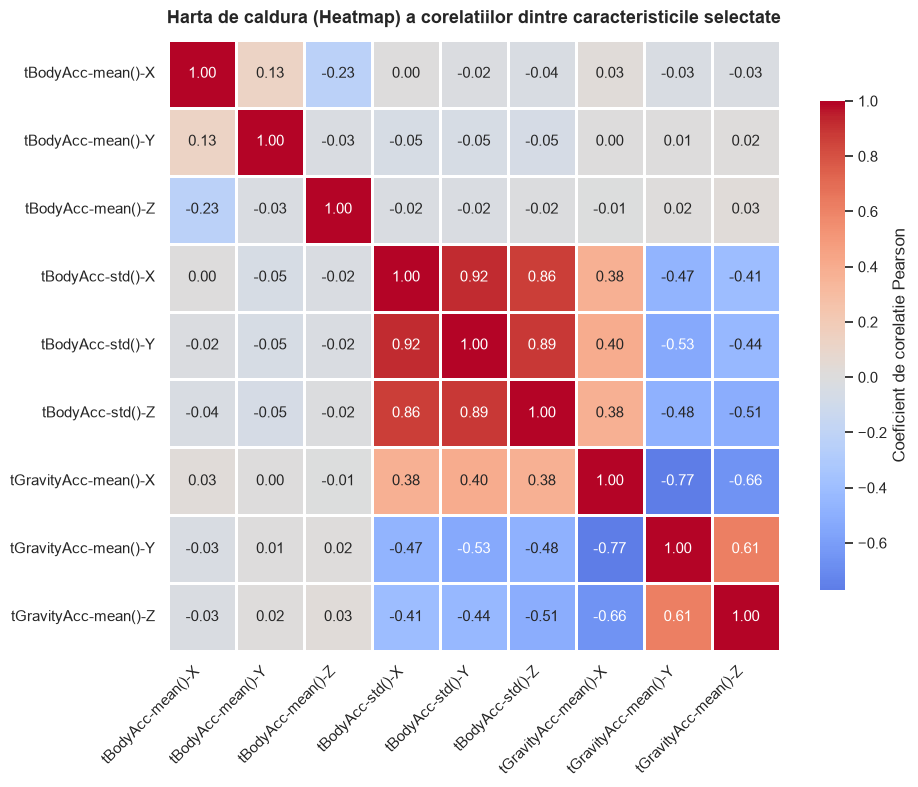

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Setari estetice generale
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11

# 1. Grafic scatter care afiseaza relatia dintre doua coloane numerice
# Alegem 'tBodyAcc-mean()-X' si 'tBodyAcc-mean()-Y', colorate dupa activitate
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='tBodyAcc-mean()-X',
    y='tBodyAcc-mean()-Y',
    hue='Activity',
    palette='tab10',
    alpha=0.6,
    s=35
)
plt.title('Diagrama de dispersie (Scatter Plot): tBodyAcc-mean()-X vs tBodyAcc-mean()-Y', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('tBodyAcc-mean()-X (Acceleratie medie axa X)', fontsize=11)
plt.ylabel('tBodyAcc-mean()-Y (Acceleratie medie axa Y)', fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, title='Activitate')
plt.tight_layout()
plt.show()

# 2. Harta de caldura (Heatmap) a corelatiilor dintre coloane
# Selectam un subset de caracteristici fizice reprezentative pentru o vizualizare clara
reprezentative_cols = [
    'tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z',
    'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z',
    'tGravityAcc-mean()-X', 'tGravityAcc-mean()-Y', 'tGravityAcc-mean()-Z'
]

corr_matrix = df[reprezentative_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.75,
    cbar_kws={"shrink": 0.8, "label": "Coeficient de corelatie Pearson"}
)
plt.title('Harta de caldura (Heatmap) a corelatiilor dintre caracteristicile selectate', fontsize=13, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 3. Metrici ale erorii
1. Împarte setul de date în seturi de antrenare și testare (80%-20%).
2. Construiește un model de regresie liniară pe datele numerice.
3. Evaluează performanța modelului utilizând **MAE**, **MSE**, și **RMSE**.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

date_numerice = df.drop(columns=['Activity'])

target_col = 'tBodyAcc-mean()-X'
X_reg = date_numerice.drop(columns=[target_col])
y_reg = date_numerice[target_col]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

print(f"Dimensiune set antrenare regresie: {X_train_r.shape}")
print(f"Dimensiune set testare regresie:   {X_test_r.shape}")

model_reg = LinearRegression()
model_reg.fit(X_train_r, y_train_r)

y_pred_r = model_reg.predict(X_test_r)

mae = mean_absolute_error(y_test_r, y_pred_r)
mse = mean_squared_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_r, y_pred_r)

print("\n" + "="*50)
print("METRICI DE PERFORMANTA PENTRU REGRESIA LINIARA")
print("="*50)
print(f"MAE  (Mean Absolute Error):       {mae:.6f}")
print(f"MSE  (Mean Squared Error):        {mse:.6f}")
print(f"RMSE (Root Mean Squared Error):   {rmse:.6f}")
print(f"R^2   (Coeficient de determinare): {r2:.6f}")


Dimensiune set antrenare regresie: (8239, 560)
Dimensiune set testare regresie:   (2060, 560)

METRICI DE PERFORMANTA PENTRU REGRESIA LINIARA
MAE  (Mean Absolute Error):       0.023176
MSE  (Mean Squared Error):        0.001547
RMSE (Root Mean Squared Error):   0.039331
R^2   (Coeficient de determinare): 0.688032



## 4. Validare încrucișată (Cross Validation)
1. Importă biblioteca `scikit-learn`.
2. Împarte setul de date în seturi de antrenare și testare (80%-20%).
3. Utilizează `cross_val_score` pentru a evalua performanța unui model KNN pe setul de date.


In [4]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score

X = df.drop(columns=['Activity'])
y = df['Activity']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Dimensiune set antrenare (80%): {X_train.shape}")
print(f"Dimensiune set testare (20%):   {X_test.shape}")

knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)

cv_scores = cross_val_score(knn, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)

print("\n" + "="*50)
print("REZULTATE VALIDARE INCRUCISATA (KNN - 5 Folds)")
print("="*50)
for fold_idx, score in enumerate(cv_scores, 1):
    print(f"Fold {fold_idx}: Acuratete = {score:.4f} ({score*100:.2f}%)")

print("-" * 50)
print(f"Acuratetea medie CV:     {cv_scores.mean():.4f} ({cv_scores.mean()*100:.2f}%)")
print(f"Deviatia standard CV:    {cv_scores.std():.4f}")

knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
acc_test_knn = accuracy_score(y_test, y_pred_knn)
print(f"Acuratetea pe setul de testare (Hold-out 20%): {acc_test_knn:.4f} ({acc_test_knn*100:.2f}%)")


Dimensiune set antrenare (80%): (8239, 561)
Dimensiune set testare (20%):   (2060, 561)

REZULTATE VALIDARE INCRUCISATA (KNN - 5 Folds)
Fold 1: Acuratete = 0.9684 (96.84%)
Fold 2: Acuratete = 0.9636 (96.36%)
Fold 3: Acuratete = 0.9660 (96.60%)
Fold 4: Acuratete = 0.9660 (96.60%)
Fold 5: Acuratete = 0.9654 (96.54%)
--------------------------------------------------
Acuratetea medie CV:     0.9659 (96.59%)
Deviatia standard CV:    0.0016
Acuratetea pe setul de testare (Hold-out 20%): 0.9646 (96.46%)



## 5. Modele de Machine Learning
1. **Regresia liniară**: Antrenează un model de regresie liniară și evaluează performanța acestuia pe setul de testare.
2. **Regresia logistică**: Construiește un model logistic pentru o problemă de clasificare binară.
3. **SVM**: Antrenează un model SVM și testează-l pe setul de date.


1. MODEL REGRESIE LINIARA - EVALUARE PE SETUL DE TESTARE
MAE:  0.004662
MSE:  0.000109
RMSE: 0.010427
R^2:   0.999617


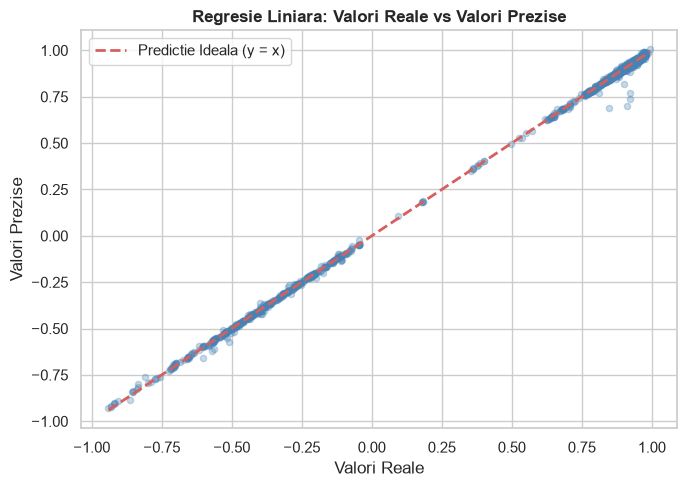

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

target_col_5 = 'tGravityAcc-mean()-X'
X_reg_task = df.drop(columns=['Activity', target_col_5])
y_reg_task = df[target_col_5]

X_tr_lin, X_te_lin, y_tr_lin, y_te_lin = train_test_split(
    X_reg_task, y_reg_task, test_size=0.20, random_state=42
)

model_lin = LinearRegression()
model_lin.fit(X_tr_lin, y_tr_lin)

y_pred_lin = model_lin.predict(X_te_lin)

mae_lin = mean_absolute_error(y_te_lin, y_pred_lin)
mse_lin = mean_squared_error(y_te_lin, y_pred_lin)
rmse_lin = np.sqrt(mse_lin)
r2_lin = r2_score(y_te_lin, y_pred_lin)

print("="*50)
print("1. MODEL REGRESIE LINIARA - EVALUARE PE SETUL DE TESTARE")
print("="*50)
print(f"MAE:  {mae_lin:.6f}")
print(f"MSE:  {mse_lin:.6f}")
print(f"RMSE: {rmse_lin:.6f}")
print(f"R^2:   {r2_lin:.6f}")

plt.figure(figsize=(7, 5))
plt.scatter(y_te_lin, y_pred_lin, alpha=0.3, color='steelblue', s=20)
plt.plot([y_te_lin.min(), y_te_lin.max()], [y_te_lin.min(), y_te_lin.max()], 'r--', lw=2, label='Predictie Ideala (y = x)')
plt.title('Regresie Liniara: Valori Reale vs Valori Prezise', fontsize=12, fontweight='bold')
plt.xlabel('Valori Reale')
plt.ylabel('Valori Prezise')
plt.legend()
plt.tight_layout()
plt.show()


2. REGRESIE LOGISTICA (CLASIFICARE BINARA: WALKING vs ALTELE)
Acuratete pe setul de testare: 0.9985 (99.85%)
Scor ROC-AUC:                  1.0000

Raport detaliat de clasificare:
              precision    recall  f1-score   support

       Other       1.00      1.00      1.00      1716
     WALKING       0.99      1.00      1.00       344

    accuracy                           1.00      2060
   macro avg       1.00      1.00      1.00      2060
weighted avg       1.00      1.00      1.00      2060



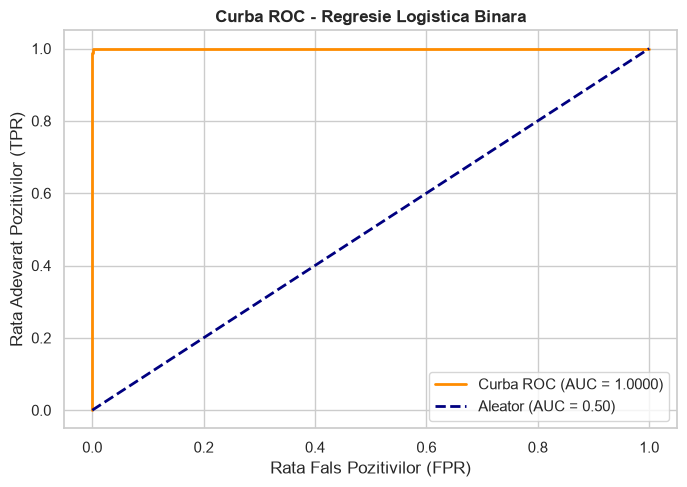

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, roc_curve

# 5.2 Regresia Logistica: Problema de clasificare binara
# Clasificam activitatea de mers ('WALKING') vs celelalte activitati (1 = WALKING, 0 = Non-WALKING)
y_bin = (df['Activity'] == 'WALKING').astype(int)
X_features = df.drop(columns=['Activity'])

X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X_features, y_bin, test_size=0.20, random_state=42, stratify=y_bin
)

model_logreg = LogisticRegression(max_iter=1000, random_state=42)
model_logreg.fit(X_train_bin, y_train_bin)

y_pred_bin = model_logreg.predict(X_test_bin)
y_prob_bin = model_logreg.predict_proba(X_test_bin)[:, 1]

acc_bin = accuracy_score(y_test_bin, y_pred_bin)
roc_auc = roc_auc_score(y_test_bin, y_prob_bin)

print("="*50)
print("2. REGRESIE LOGISTICA (CLASIFICARE BINARA: WALKING vs ALTELE)")
print("="*50)
print(f"Acuratete pe setul de testare: {acc_bin:.4f} ({acc_bin*100:.2f}%)")
print(f"Scor ROC-AUC:                  {roc_auc:.4f}")
print("\nRaport detaliat de clasificare:")
print(classification_report(y_test_bin, y_pred_bin, target_names=['Other', 'WALKING']))

# Curba ROC
fpr, tpr, _ = roc_curve(y_test_bin, y_prob_bin)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curba ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Aleator (AUC = 0.50)')
plt.xlabel('Rata Fals Pozitivilor (FPR)')
plt.ylabel('Rata Adevarat Pozitivilor (TPR)')
plt.title('Curba ROC - Regresie Logistica Binara', fontsize=12, fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


In [7]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# 5.3 SVM (Support Vector Machine): Antrenare si testare pe setul de date
model_svm = LinearSVC(max_iter=2000, random_state=42)
model_svm.fit(X_train, y_train)

y_pred_svm = model_svm.predict(X_test)
acc_svm = accuracy_score(y_test, y_pred_svm)

print("="*50)
print("3. MODEL SVM (SUPPORT VECTOR MACHINE)")
print("="*50)
print(f"Acuratete pe setul de testare: {acc_svm:.4f} ({acc_svm*100:.2f}%)")
print("\nRaport complet de clasificare SVM pe toate cele 6 activitati:")
print(classification_report(y_test, y_pred_svm))


3. MODEL SVM (SUPPORT VECTOR MACHINE)
Acuratete pe setul de testare: 0.9874 (98.74%)

Raport complet de clasificare SVM pe toate cele 6 activitati:
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       389
           SITTING       0.97      0.96      0.97       356
          STANDING       0.97      0.97      0.97       381
           WALKING       0.99      1.00      1.00       344
WALKING_DOWNSTAIRS       1.00      1.00      1.00       281
  WALKING_UPSTAIRS       1.00      0.99      1.00       309

          accuracy                           0.99      2060
         macro avg       0.99      0.99      0.99      2060
      weighted avg       0.99      0.99      0.99      2060



In [8]:
# Comparatie sinoptica a performantelor modelelor evaluate in Sectiunea 5
print("="*60)
print("REZUMAT PERFORMANTA MODELE EVALUATE (SECTIUNEA 5)")
print("="*60)
summary_data = {
    'Model': ['Regresie Liniara (Target continuu)', 'Regresie Logistica (Binar: WALKING)', 'SVM (Multiclasa: 6 activitati)'],
    'Tip Problema': ['Regresie', 'Clasificare Binara', 'Clasificare Multiclasa'],
    'Metrica Principala': [f"R^2 = {r2_lin:.4f}, RMSE = {rmse_lin:.4f}", f"Acuratete = {acc_bin*100:.2f}%, AUC = {roc_auc:.4f}", f"Acuratete = {acc_svm*100:.2f}%"]
}
df_summary = pd.DataFrame(summary_data)
display(df_summary)


REZUMAT PERFORMANTA MODELE EVALUATE (SECTIUNEA 5)


,Model,Tip Problema,Metrica Principala
0,Regresie Liniara (Target continuu),Regresie,"R^2 = 0.9996, RMSE = 0.0104"
1,Regresie Logistica (Binar: WALKING),Clasificare Binara,"Acuratete = 99.85%, AUC = 1.0000"
2,SVM (Multiclasa: 6 activitati),Clasificare Multiclasa,Acuratete = 98.74%


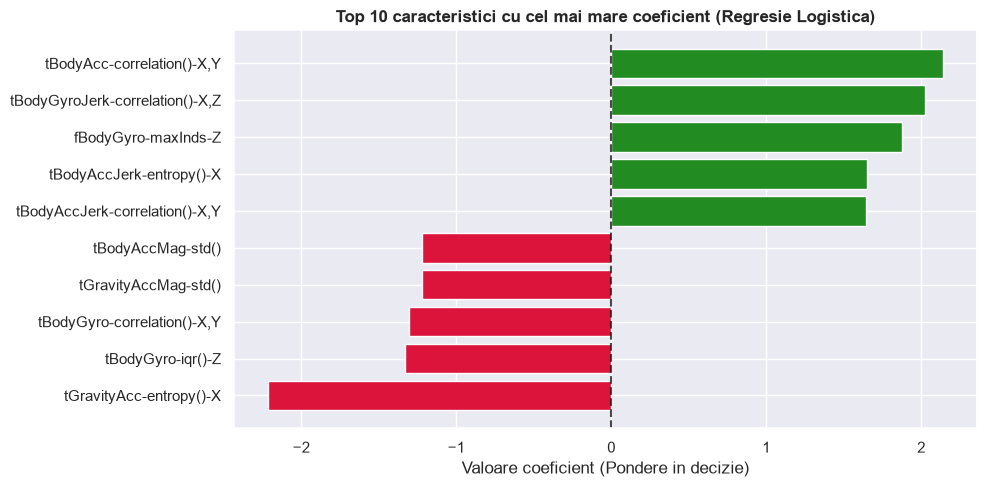

In [9]:
# Analiza celor mai influente caracteristici pentru modelul de clasificare binara
coef = model_logreg.coef_[0]
feature_names = np.array(X_features.columns)

top_pos_idx = np.argsort(coef)[-5:]
top_neg_idx = np.argsort(coef)[:5]

top_indices = np.concatenate([top_neg_idx, top_pos_idx])
top_features = feature_names[top_indices]
top_coefficients = coef[top_indices]

plt.figure(figsize=(10, 5))
colors = ['crimson' if c < 0 else 'forestgreen' for c in top_coefficients]
plt.barh(top_features, top_coefficients, color=colors)
plt.axvline(0, color='black', linestyle='--', alpha=0.7)
plt.title('Top 10 caracteristici cu cel mai mare coeficient (Regresie Logistica)', fontsize=12, fontweight='bold')
plt.xlabel('Valoare coeficient (Pondere in decizie)')
plt.tight_layout()
plt.show()


## 6. Matricea de confuzie
1. Construiește un model de clasificare logistică.
2. Creează matricea de confuzie și afișează-o grafic utilizând Seaborn.

MATRICEA DE CONFUZIE - REGRESIE LOGISTICA MULTICLASA
Acuratetea modelului pe test: 0.9864 (98.64%)



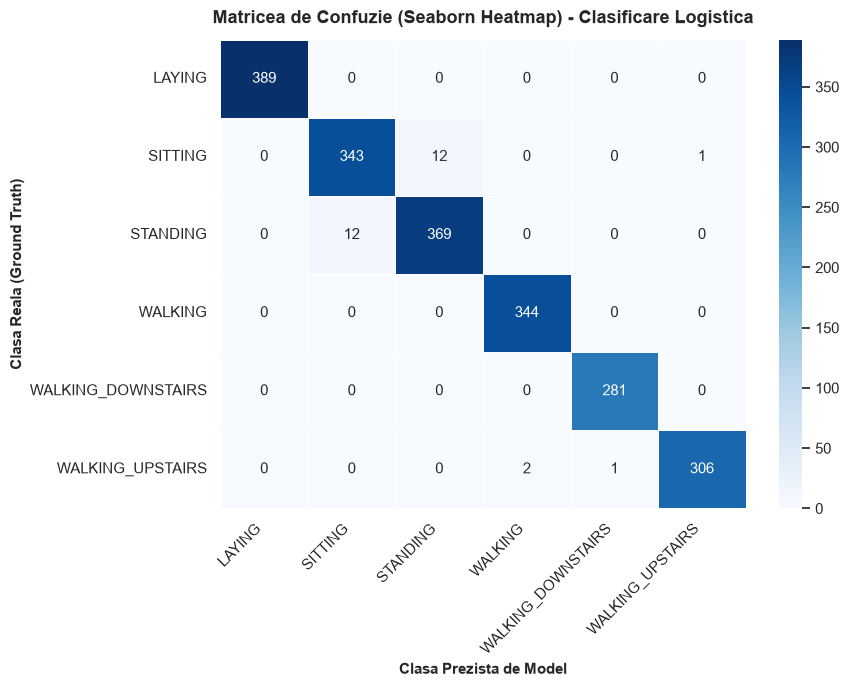

Raport detaliat de clasificare:
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       389
           SITTING       0.97      0.96      0.96       356
          STANDING       0.97      0.97      0.97       381
           WALKING       0.99      1.00      1.00       344
WALKING_DOWNSTAIRS       1.00      1.00      1.00       281
  WALKING_UPSTAIRS       1.00      0.99      0.99       309

          accuracy                           0.99      2060
         macro avg       0.99      0.99      0.99      2060
      weighted avg       0.99      0.99      0.99      2060



In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

# 6.1 Construirea modelului de clasificare logistica multiclasa
model_lr_multi = LogisticRegression(max_iter=1000, random_state=42)
model_lr_multi.fit(X_train, y_train)

y_pred_multi = model_lr_multi.predict(X_test)
acc_multi = accuracy_score(y_test, y_pred_multi)

print("="*50)
print("MATRICEA DE CONFUZIE - REGRESIE LOGISTICA MULTICLASA")
print("="*50)
print(f"Acuratetea modelului pe test: {acc_multi:.4f} ({acc_multi*100:.2f}%)\n")

# 6.2 Crearea matricei de confuzie si afisarea grafica utilizand Seaborn
labels = np.unique(y_test)
cm = confusion_matrix(y_test, y_pred_multi, labels=labels)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels,
    cbar=True,
    linewidths=0.5
)
plt.title('Matricea de Confuzie (Seaborn Heatmap) - Clasificare Logistica', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Clasa Prezista de Model', fontsize=11, fontweight='bold')
plt.ylabel('Clasa Reala (Ground Truth)', fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Raport detaliat de clasificare:")
print(classification_report(y_test, y_pred_multi))



## 7. Gradient Descent
1. Implementați manual algoritmul Gradient Descent pentru a optimiza o funcție cost definită.
2. Utilizați o funcție simplă $$J(\theta) = (\theta x - y)^2 $$ pe un subset al datelor.

REZULTATE GRADIENT DESCENT MANUAL
Valoarea initiala theta:          0.0
Rata de invatare (alpha):         0.3
Numar de iteratii:                80
Cost initial J(theta_0):          0.741464
Cost final J(theta_final):        0.000677
Theta obtinut prin GD:            1.006707
Theta analitic optim (teoretic):  1.006707
Diferenta absoluta:               0.00000000


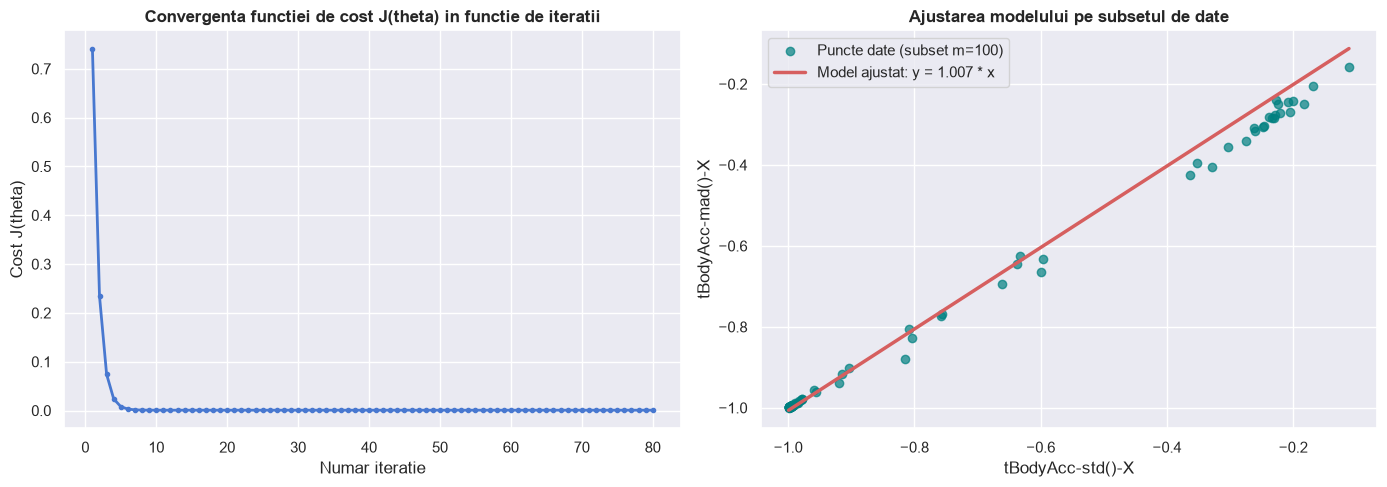

In [11]:
# 7. Gradient Descent implementat manual
# Functia cost: J(theta) = (1/m) * sum((theta * x - y)^2) pe un subset al datelor

# 1. Selectam un subset de date (m=100) si doua coloane puternic corelate
subset_size = 100
subset = df.iloc[:subset_size]
x_val = subset['tBodyAcc-std()-X'].values
y_val = subset['tBodyAcc-mad()-X'].values

def compute_cost(x, y, theta):
    m = len(y)
    return (1.0 / m) * np.sum((theta * x - y)**2)

def compute_gradient(x, y, theta):
    m = len(y)
    return (2.0 / m) * np.sum((theta * x - y) * x)

def gradient_descent(x, y, initial_theta=0.0, alpha=0.3, iterations=100):
    theta = initial_theta
    cost_history = []
    theta_history = []
    
    for i in range(iterations):
        cost = compute_cost(x, y, theta)
        grad = compute_gradient(x, y, theta)
        theta = theta - alpha * grad
        
        cost_history.append(cost)
        theta_history.append(theta)
        
    return theta, cost_history, theta_history

# Rularea algoritmului
theta_initial = 0.0
alpha_rate = 0.3
num_iterations = 80

theta_final, cost_hist, theta_hist = gradient_descent(
    x_val, y_val, initial_theta=theta_initial, alpha=alpha_rate, iterations=num_iterations
)

# Solutia optima exacta (analitica): theta* = sum(x*y) / sum(x^2)
theta_analytical = np.sum(x_val * y_val) / np.sum(x_val**2)

print("="*50)
print("REZULTATE GRADIENT DESCENT MANUAL")
print("="*50)
print(f"Valoarea initiala theta:          {theta_initial}")
print(f"Rata de invatare (alpha):         {alpha_rate}")
print(f"Numar de iteratii:                {num_iterations}")
print(f"Cost initial J(theta_0):          {cost_hist[0]:.6f}")
print(f"Cost final J(theta_final):        {cost_hist[-1]:.6f}")
print(f"Theta obtinut prin GD:            {theta_final:.6f}")
print(f"Theta analitic optim (teoretic):  {theta_analytical:.6f}")
print(f"Diferenta absoluta:               {abs(theta_final - theta_analytical):.8f}")

# Vizualizarea convergentei si a dreptei ajustate
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, num_iterations + 1), cost_hist, 'b-', lw=2, marker='o', markersize=3)
axes[0].set_title('Convergenta functiei de cost J(theta) in functie de iteratii', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Numar iteratie')
axes[0].set_ylabel('Cost J(theta)')
axes[0].grid(True)

axes[1].scatter(x_val, y_val, color='teal', alpha=0.7, label='Puncte date (subset m=100)')
x_line = np.linspace(x_val.min(), x_val.max(), 100)
axes[1].plot(x_line, theta_final * x_line, 'r-', lw=2.5, label=f'Model ajustat: y = {theta_final:.3f} * x')
axes[1].set_title('Ajustarea modelului pe subsetul de date', fontsize=12, fontweight='bold')
axes[1].set_xlabel('tBodyAcc-std()-X')
axes[1].set_ylabel('tBodyAcc-mad()-X')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


## 8. Modele de Machine Learning (part 2 - poate fi omis)
1. **Random Forest**: Utilizează Random Forest pentru a antrena un model și evaluează importanța caracteristicilor.
2. **Boosting și Bagging**: Compară performanța dintre un model AdaBoost și un model Bagging.


1. RANDOM FOREST - EVALUARE SI IMPORTANTA CARACTERISTICILOR
Acuratetea modelului Random Forest pe test: 0.9816 (98.16%)



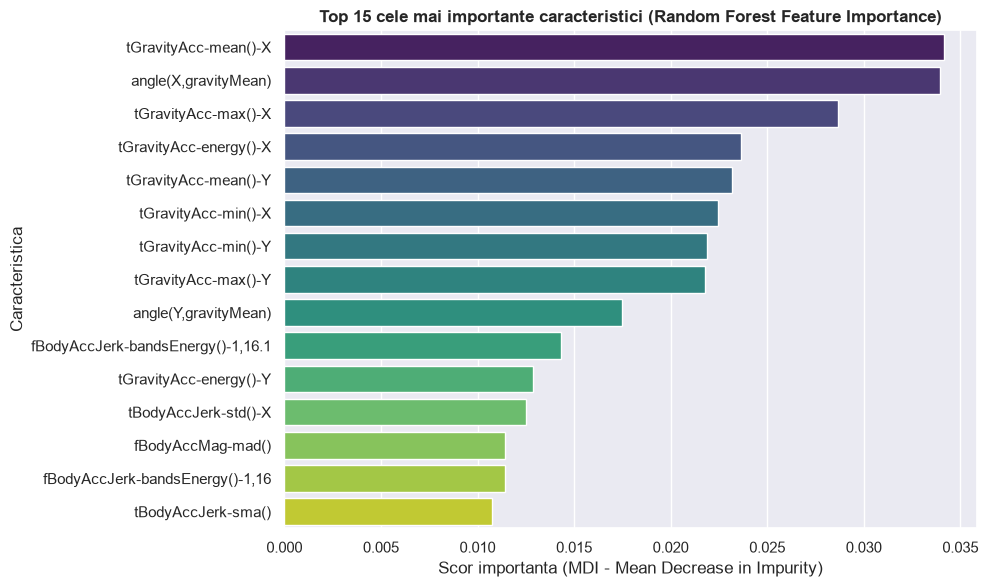

In [12]:
from sklearn.ensemble import RandomForestClassifier

# 8.1 Random Forest: Antrenare si evaluarea importantei caracteristicilor
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)

print("="*50)
print("1. RANDOM FOREST - EVALUARE SI IMPORTANTA CARACTERISTICILOR")
print("="*50)
print(f"Acuratetea modelului Random Forest pe test: {acc_rf:.4f} ({acc_rf*100:.2f}%)\n")

# Extragerea si vizualizarea importantei caracteristicilor
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
top_15_features = feature_importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_15_features.values, y=top_15_features.index, hue=top_15_features.index, palette='viridis', legend=False)
plt.title('Top 15 cele mai importante caracteristici (Random Forest Feature Importance)', fontsize=12, fontweight='bold')
plt.xlabel('Scor importanta (MDI - Mean Decrease in Impurity)')
plt.ylabel('Caracteristica')
plt.tight_layout()
plt.show()


2. COMPARATIE PERFORMANTA: ADABOOST VS BAGGING
Acuratete Model Bagging:  0.9670 (96.70%)
Acuratete Model AdaBoost: 0.9859 (98.59%)


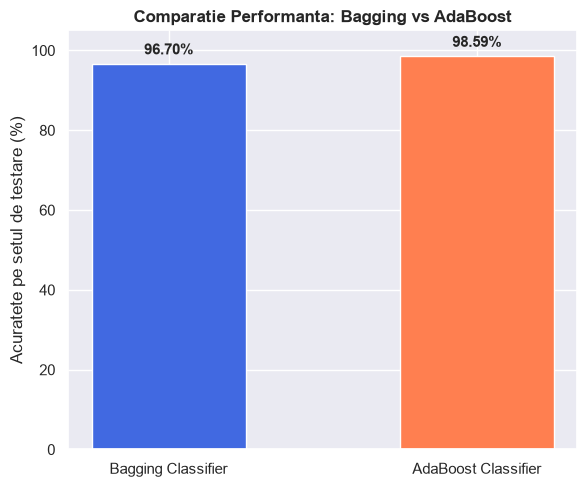

In [13]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# 8.2 Boosting si Bagging: Compararea performantei dintre AdaBoost si Bagging
print("="*50)
print("2. COMPARATIE PERFORMANTA: ADABOOST VS BAGGING")
print("="*50)

# Model Bagging (foloseste arbori decizionali complet dezvoltati, max_depth=None)
bagging_model = BaggingClassifier(n_estimators=30, random_state=42, n_jobs=-1)
bagging_model.fit(X_train, y_train)
y_pred_bag = bagging_model.predict(X_test)
acc_bag = accuracy_score(y_test, y_pred_bag)

# Model AdaBoost cu estimator de baza adecvat (max_depth=3)
# Implicit, AdaBoost foloseste DecisionTreeClassifier(max_depth=1) (decision stump),
# care este prea slab pentru un dataset multiclasa (6 clase) si 561 de trasaturi (subinvatare severa => ~35%).
# Folosind un estimator cu adancime moderata (max_depth=3), modelul surprinde interactiunile complexe.
base_estimator = DecisionTreeClassifier(max_depth=3)
adaboost_model = AdaBoostClassifier(
    estimator=base_estimator,
    n_estimators=50,
    learning_rate=0.5,
    random_state=42
)
adaboost_model.fit(X_train, y_train)
y_pred_ada = adaboost_model.predict(X_test)
acc_ada = accuracy_score(y_test, y_pred_ada)

print(f"Acuratete Model Bagging:  {acc_bag:.4f} ({acc_bag*100:.2f}%)")
print(f"Acuratete Model AdaBoost: {acc_ada:.4f} ({acc_ada*100:.2f}%)")

# Comparatie grafica
plt.figure(figsize=(6, 5))
methods = ['Bagging Classifier', 'AdaBoost Classifier']
accuracies = [acc_bag * 100, acc_ada * 100]
bars = plt.bar(methods, accuracies, color=['royalblue', 'coral'], width=0.5)
plt.ylabel('Acuratete pe setul de testare (%)')
plt.title('Comparatie Performanta: Bagging vs AdaBoost', fontsize=12, fontweight='bold')
plt.ylim(0, 105)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


## 9. Stacking
1. Construiește un model de tip Stacking utilizând Random Forest, SVM și Logistic Regression ca modele de bază.
2. Utilizează un model Logistic Regression ca meta-model.
3. Afișează acuratețea finală pe setul de testare.

In [14]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 9. Construirea unui model de tip Stacking
# 1. Modele de baza: Random Forest, SVM (LinearSVC) si Logistic Regression
base_estimators = [
    ('rf', RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)),
    ('svm', LinearSVC(max_iter=2000, random_state=42)),
    ('lr', LogisticRegression(max_iter=1000, random_state=42))
]

# 2. Meta-model: Logistic Regression
meta_model = LogisticRegression(max_iter=1000, random_state=42)

# Construim clasificatorul Stacking utilizand validare incrucisata interna (cv=3)
stacking_clf = StackingClassifier(
    estimators=base_estimators,
    final_estimator=meta_model,
    cv=3,
    n_jobs=-1
)

print('Antrenare model Stacking in curs...')
stacking_clf.fit(X_train, y_train)

# 3. Predictii si afisarea acuratetei finale pe setul de testare
y_pred_stack = stacking_clf.predict(X_test)
acc_stack = accuracy_score(y_test, y_pred_stack)

print('\n' + '='*50)
print('REZULTATE FINALE MODEL STACKING')
print('='*50)
print(f'Acuratetea finala a modelului Stacking pe setul de testare: {acc_stack:.4f} ({acc_stack*100:.2f}%)')

print('\nRaport de clasificare detaliat (Stacking Classifier):')
print(classification_report(y_test, y_pred_stack))

# Comparatie acuratete intre modelele de baza si modelul Stacking
# Antrenam modelele de baza separat pe tot X_train pentru comparatie directa
print('='*50)
print('COMPARATIE ACURATETE: MODELE INDIVIDUALE VS STACKING')
print('='*50)

rf_base = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
rf_base.fit(X_train, y_train)
acc_rf_base = accuracy_score(y_test, rf_base.predict(X_test)) * 100

svm_base = LinearSVC(max_iter=2000, random_state=42)
svm_base.fit(X_train, y_train)
acc_svm_base = accuracy_score(y_test, svm_base.predict(X_test)) * 100

lr_base = LogisticRegression(max_iter=1000, random_state=42)
lr_base.fit(X_train, y_train)
acc_lr_base = accuracy_score(y_test, lr_base.predict(X_test)) * 100

model_names = ['Random Forest (Base)', 'Linear SVM (Base)', 'Logistic Reg (Base)', 'Stacking Classifier (Ensemble)']
acc_scores = [acc_rf_base, acc_svm_base, acc_lr_base, acc_stack * 100]

for name, score in zip(model_names, acc_scores):
    print(f'{name:<35}: {score:.2f}%')


Antrenare model Stacking in curs...

REZULTATE FINALE MODEL STACKING
Acuratetea finala a modelului Stacking pe setul de testare: 0.9913 (99.13%)

Raport de clasificare detaliat (Stacking Classifier):
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       389
           SITTING       0.97      0.98      0.98       356
          STANDING       0.98      0.98      0.98       381
           WALKING       0.99      1.00      1.00       344
WALKING_DOWNSTAIRS       1.00      1.00      1.00       281
  WALKING_UPSTAIRS       1.00      0.99      1.00       309

          accuracy                           0.99      2060
         macro avg       0.99      0.99      0.99      2060
      weighted avg       0.99      0.99      0.99      2060

COMPARATIE ACURATETE: MODELE INDIVIDUALE VS STACKING
Random Forest (Base)               : 98.25%
Linear SVM (Base)                  : 98.74%
Logistic Reg (Base)                : 98.64%
Stacking Cla


## Observații
Te rog, să salvezi  și să predai acest notebook după ce ai completat toate secțiunile.
